# **Welcome to the Earth Lab & ESIIL Environmental Data Science Workshop**

Welcome to this hands-on workshop hosted at **Sinte Gleska University** in partnership with Earth Lab, and the Environmental Data Science Innovation and Impact Lab (ESIIL). This workshop is designed to help you build practical skills in coding, data analysis, and artificial intelligence (AI) using real environmental and community-relevant data.

Throughout the workshop, you will explore tools commonly used in today’s workforce, including Python, Jupyter Notebooks, cloud-based computing environments, APIs, and AI-assisted workflows. No matter your previous coding experience, the goal is to create a supportive learning environment where you can experiment, ask questions, and develop confidence working with data and technology.

By the end of the workshop, you will have experience using open data science tools to investigate environmental questions, create visualizations, and explore how AI can support research, decision-making, and future career opportunities across many fields.

![https://www.indianz.com/News/2015/09/03/sintegleskauniversity.jpg](https://www.indianz.com/News/2015/09/03/sintegleskauniversity.jpg)

# Mapping Sinte Gleska University with OpenStreetMap

In this notebook, we will use Python to create maps of the Sinte Gleska University campus and the surrounding area.

We will use data from **OpenStreetMap**, which is a free, publicly available source of geographic information. Using OpenStreetMap data, we will map the campus boundary, buildings, roads, and water features near campus. You can explore OpenStreetMap here: [https://www.openstreetmap.org](https://www.openstreetmap.org). Let's spend a few mintues exploring their online search tool before diving into the code.

As we work through the notebook, we will build the map one layer at a time. At the end, we will combine the layers into one interactive map that you can zoom, pan, and explore.

## Install and import Python packages

Before we can make our maps, we need to load a few Python packages.

The first line installs the packages we need. If you already have these packages installed, you may not need to run it again.

We will use:

- `osmnx` to download map data from OpenStreetMap
- `geopandas` to work with spatial data
- `matplotlib` to make simple static maps
- `hvplot` to make interactive maps

In [2]:
# If needed, uncomment and run:

import osmnx as ox
import geopandas as gpd
import matplotlib.pyplot as plt
import hvplot.pandas
import xyzservices.providers as xyz


## Set the place name and search distance

In this step, we will create two variables that control our OpenStreetMap search.

The `place_name` variable tells Python what location we want to search for. In this case, we are searching for Sinte Gleska University in Mission, South Dakota.

The `search_distance` variable controls how far away from campus we want to search for nearby features like roads and water. This distance is measured in **meters**.

Fill in the blanks below to create both variables.

In [3]:
# -----------------------------
# Set place name and search distance
# -----------------------------

place_name = "Sinte Gleska University"
search_distance = 2000

## Find the campus boundary

Now we will use OpenStreetMap to search for the Sinte Gleska University campus boundary.

The function `ox.geocode_to_gdf()` searches for a place name and returns the result as a GeoDataFrame.

A **GeoDataFrame** is like a table, but it also includes a geometry column that stores shapes, such as points, lines, or polygons.

In the code cell below, fill in the blanks for the variable name and the argument inside `ox.geocode_to_gdf()`.

In [4]:
# -----------------------------
# Find campus boundary
# -----------------------------

sgu_boundary = ox.geocode_to_gdf(place_name)

sgu_boundary

,geometry,bbox_west,bbox_south,bbox_east,bbox_north,place_id,osm_type,osm_id,lat,lon,class,type,place_rank,importance,addresstype,name,display_name
0,"MULTIPOLYGON (((-100.65351 43.30407, -100.6528...",-100.653508,43.296903,-100.618705,43.308667,327139075,relation,15626065,43.298906,-100.621154,amenity,university,30,0.321249,amenity,Sinte Gleska University,"Sinte Gleska University, Blue Star Memorial Hi..."


## Plot the campus boundary

Now that we have downloaded the campus boundary, we can make our first map.

The `.plot()` method creates a simple static map from a GeoDataFrame.

In this example, we will plot the campus boundary as an outline. The `edgecolor` controls the outline color, `facecolor` controls the inside fill color, and `linewidth` controls how thick the boundary line is.

In the code cell below, fill in the blanks for the GeoDataFrame name, plotting parameters, and map title.

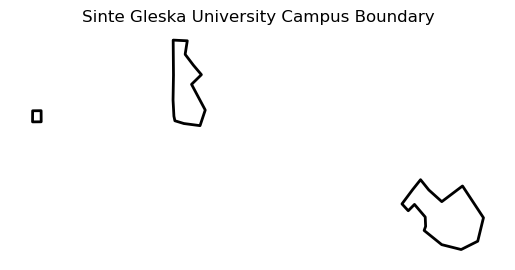

In [5]:
# -----------------------------
# Plot campus boundary
# -----------------------------

sgu_boundary.plot(
    edgecolor="black",
    facecolor="none",
    linewidth=2
)

plt.title("Sinte Gleska University Campus Boundary")
plt.axis("off")
plt.show()

## Get the campus polygon

Next, we need to select the actual campus boundary shape from our GeoDataFrame.

The boundary GeoDataFrame contains a `geometry` column. This column stores the spatial shape of the campus.

The code below uses `.geometry.iloc[0]` to select the first geometry in the GeoDataFrame. We will save that shape as a new variable so we can use it to search for buildings inside the campus boundary.

Fill in the blanks for the new polygon variable name and the GeoDataFrame name.

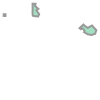

In [6]:
# -----------------------------
# Get campus polygon
# -----------------------------

sgu_polygon = sgu_boundary.geometry.iloc[0]

sgu_polygon

## Find buildings inside the campus boundary

Now we will search OpenStreetMap for buildings inside the campus polygon.

OpenStreetMap uses **tags** to describe different types of map features. For buildings, we can use the tag `{"building": True}`. This means we want to find any feature that has been marked as a building.

The function `ox.features_from_polygon()` searches for features inside a polygon. In this case, the polygon is the campus boundary we created in the previous step.

Fill in the blanks for the building tag, the buildings GeoDataFrame name, and the tags argument.

In [7]:
# -----------------------------
# Find buildings inside campus boundary
# -----------------------------

building_tags = {"building": True}

sgu_buildings = ox.features_from_polygon(
    sgu_polygon,
    tags=building_tags
)

sgu_buildings

geometry  \
element id                                                              
way     1329989373  POLYGON ((-100.6225 43.29803, -100.62206 43.29...   
        1329989674  POLYGON ((-100.62091 43.29774, -100.6209 43.29...   
        1329989763  POLYGON ((-100.6199 43.29795, -100.61967 43.29...   
        1329990142  POLYGON ((-100.61943 43.2987, -100.61948 43.29...   
        1329990226  POLYGON ((-100.62064 43.29949, -100.62064 43.2...   
        1329990342  POLYGON ((-100.62158 43.29887, -100.6216 43.29...   
        1329990737  POLYGON ((-100.62043 43.29875, -100.62053 43.2...   
        1329990805  POLYGON ((-100.62361 43.30024, -100.62345 43.3...   
        1329991082  POLYGON ((-100.62219 43.29901, -100.62286 43.2...   
        1329992072  POLYGON ((-100.64257 43.30818, -100.64257 43.3...   
        1329992618  POLYGON ((-100.64223 43.30744, -100.64232 43.3...   
        1329992860  POLYGON ((-100.64186 43.30503, -100.64148 43.3...   
        1329993273  POLYGON ((-100.64186 43.30551, -100.64187 43.3...   
        1329993577  POLYGON ((-100.64255 43.30525, -100.64254 43.3...   
        1329993817  POLYGON ((-100.64141 43.30488, -100.64141 43.3...   

                      building  \
element id                       
way     1329989373  university   
        1329989674  university   
        1329989763  university   
        1329990142  university   
        1329990226  university   
        1329990342  university   
        1329990737  university   
        1329990805  university   
        1329991082  university   
        1329992072  university   
        1329992618  university   
        1329992860  university   
        1329993273  university   
        1329993577  university   
        1329993817  university   

                                                                 name  \
element id                                                              
way     1329989373        Sinte Gleska University Technology Building   
        1329989674           Sinte Gleska University Student Services   
        1329989763   Sinte Gleska University Mike Benge Student Union   
        1329990142    Sinte Gleska University Administration Building   
        1329990226         Sinte Gleska University Business Education   
        1329990342                             SGU Tiwahe Glu Kini Pi   
        1329990737        Sinte Gleska University Lakota Studies Tipi   
        1329990805            Sinte Gleska University Heritage Center   
        1329991082      Sinte Gleska University Multipurpose Building   
        1329992072                 Sinte Gleska University Child Care   
        1329992618    Sinte Gleska University Institute of Technology   
        1329992860                    Sinte Gleska University Library   
        1329993273                  Sinte Gleska University Bookstore   
        1329993577             Sinte Gleska University Science Center   
        1329993817  Sinte Gleska University Adult Basic Education/GED   

                   addr:city addr:postcode addr:state building:levels  \
element id                                                              
way     1329989373   Mission         57555         SD               2   
        1329989674   Mission         57555         SD               1   
        1329989763   Mission         57555         SD               1   
        1329990142   Mission         57555         SD               3   
        1329990226   Mission         57555         SD               1   
        1329990342   Mission         57555         SD               2   
        1329990737   Mission         57555         SD               3   
        1329990805   Mission         57555         SD               3   
        1329991082   Mission         57555         SD               1   
        1329992072   Mission         57555         SD               1   
        1329992618   Mission         57555         SD               1   
        1329992860   Mission         57555       

## Plot the campus buildings

Next, we will create a simple map of the buildings inside the Sinte Gleska University campus boundary.

This map uses the buildings GeoDataFrame we created in the previous step. The `.plot()` method lets us control how the buildings appear on the map.

The `color` parameter controls the fill color of the buildings, `edgecolor` controls the outline color, and `linewidth` controls the thickness of the building outlines.

In the code cell below, fill in the blanks for the GeoDataFrame name, plotting parameters, and map title.

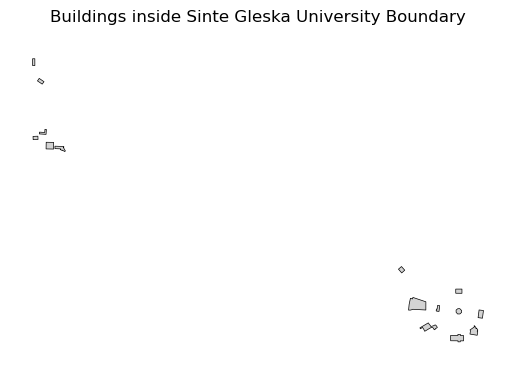

In [8]:
# -----------------------------
# Plot buildings
# -----------------------------

sgu_buildings.plot(
    color="lightgray",
    edgecolor="black",
    linewidth=0.5
)

plt.title("Buildings inside Sinte Gleska University Boundary")
plt.axis("off")
plt.show()

## Plot the campus boundary and buildings together

Now we will plot two layers on the same map: the campus boundary and the campus buildings.

To do this, we first create a figure and axis using `plt.subplots()`. The `figsize` controls the size of the map.

Then, each layer is added to the same axis using `ax=ax`. This tells Python to draw both layers on the same map instead of creating two separate maps.

In the code cell below, fill in the blanks for the figure size, GeoDataFrame names, plotting parameters, and map title.

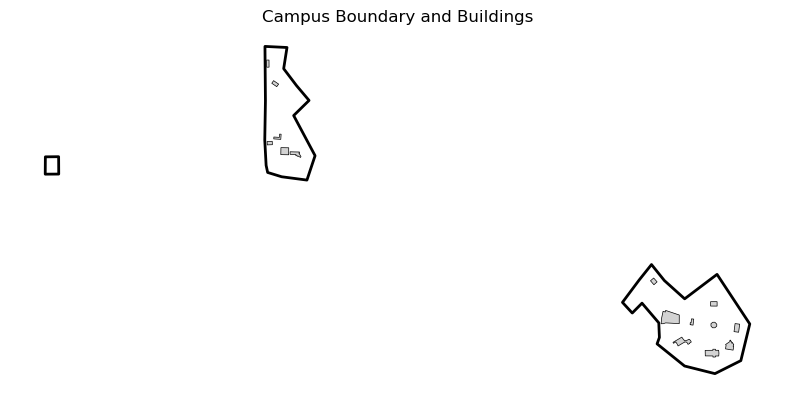

In [9]:
# -----------------------------
# Plot boundary and buildings together
# -----------------------------

fig, ax = plt.subplots(figsize=(10, 10))

sgu_boundary.plot(
    ax=ax,
    edgecolor="black",
    facecolor="none",
    linewidth=2
)

sgu_buildings.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    linewidth=0.5
)

plt.title("Campus Boundary and Buildings")
plt.axis("off")
plt.show()

## Find the center point of campus

Next, we will find the center point of the campus boundary.

This point will help us search for nearby features, such as roads and water, within a set distance of campus.

First, we make sure the boundary is in latitude and longitude coordinates using `EPSG:4326`. Then we find the center of the campus polygon using `.centroid`.

Finally, we save the center point as `center_lat_lon`, which stores the coordinates in the order expected by OSMnx: latitude first, longitude second.

You do not need to change anything in the code cell below. Run it as it is.

In [10]:
# -----------------------------
# Find center point of campus
# -----------------------------

boundary_wgs84 = sgu_boundary.to_crs(epsg=4326)

center_point = boundary_wgs84.geometry.iloc[0].centroid

center_lat_lon = (center_point.y, center_point.x)

center_lat_lon

(43.301515756756125, -100.62947380183154)

## Find roads near campus

Now we will search OpenStreetMap for roads near campus.

OpenStreetMap usually stores roads using the tag `{"highway": True}`. This does not only mean large highways. In OpenStreetMap, the `highway` tag can include many kinds of roads, streets, paths, and driveways.

The function `ox.features_from_point()` searches for features within a set distance of a point. Here, we will search around the campus center point using the `search_distance` value we created earlier.

Fill in the blanks for the road tag, the roads GeoDataFrame name, and the tags argument.

In [11]:
# -----------------------------
# Find roads near campus
# -----------------------------

road_tags = {"highway": True}

sgu_roads = ox.features_from_point(
    center_lat_lon,
    tags=road_tags,
    dist=search_distance
)

sgu_roads

geometry  \
element id                                                              
node    81133476                          POINT (-100.65267 43.30583)   
        81151121                          POINT (-100.65332 43.30002)   
        81157751                          POINT (-100.60534 43.30129)   
        81158951                          POINT (-100.65329 43.29946)   
        81159885                          POINT (-100.65156 43.30725)   
...                                                               ...   
way     1337295371  LINESTRING (-100.62856 43.30239, -100.62947 43...   
        1337295374  LINESTRING (-100.65277 43.29402, -100.65315 43...   
        1424841911  LINESTRING (-100.65353 43.29417, -100.65368 43...   
        1424841915  LINESTRING (-100.6544 43.29475, -100.65443 43....   
        1424841919  LINESTRING (-100.65402 43.29431, -100.65404 43...   

                            highway traffic_signals crossing           name  \
element id                                                                    
node    81133476    traffic_signals          signal      NaN            NaN   
        81151121     turning_circle             NaN      NaN            NaN   
        81157751     turning_circle             NaN      NaN            NaN   
        81158951     turning_circle             NaN      NaN            NaN   
        81159885       turning_loop             NaN      NaN            NaN   
...                             ...             ...      ...            ...   
way     1337295371      residential             NaN      NaN  Cheyenne Road   
        1337295374          service             NaN      NaN            NaN   
        1424841911          service             NaN      NaN            NaN   
        1424841915          service             NaN      NaN            NaN   
        1424841919          service             NaN      NaN            NaN   

                    NHS  hgv hgv:national_network lanes  ref  ...  \
element id                                                    ...   
node    81133476    NaN  NaN                  NaN   NaN  NaN  ...   
        81151121    NaN  NaN                  NaN   NaN  NaN  ...   
        81157751    NaN  NaN                  NaN   NaN  NaN  ...   
        81158951    NaN  NaN                  NaN   NaN  NaN  ...   
        81159885    NaN  NaN                  NaN   NaN  NaN  ...   
...                 ...  ...                  ...   ...  ...  ...   
way     1337295371  NaN  NaN                  NaN   NaN  NaN  ...   
        1337295374  NaN  NaN                  NaN   NaN  NaN  ...   
        1424841911  NaN  NaN                  NaN   NaN  NaN  ...   
        1424841915  NaN  NaN                  NaN   NaN  NaN  ...   
        1424841919  NaN  NaN                  NaN   NaN  NaN  ...   

                   tiger:source tiger:tlid tiger:upload_uuid        service  \
element id                                                                    
node    81133476            NaN        NaN               NaN            NaN   
        81151121            NaN        NaN               NaN            NaN   
        81157751            NaN        NaN               NaN            NaN   
        81158951            NaN        NaN               NaN            NaN   
        81159885            NaN        NaN               NaN            NaN   
...                         ...        ...               ...            ...   
way     1337295371          NaN        NaN               NaN            NaN   
        1337295374          NaN        NaN               NaN            NaN   
        1424841911          NaN        NaN               NaN            NaN   
        1424841915          NaN        NaN               NaN            NaN   
        1424841919          NaN        NaN               NaN  parking_aisle   

                   note note:lanes alt_name maxspeed bridge layer  
element id                                                         
node    81133476    N

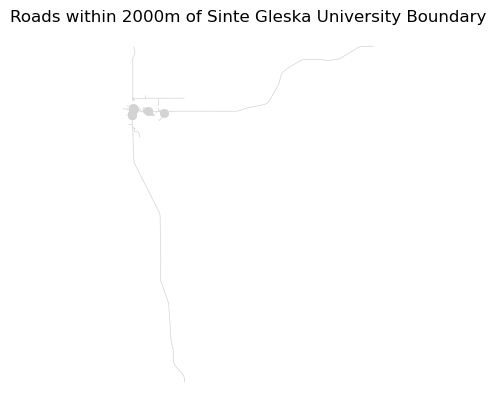

In [12]:
# -----------------------------
# Plot roads
# -----------------------------

sgu_roads.plot(
    color="lightgray",
    linewidth=0.5
)

plt.title("Roads within 2000m of Sinte Gleska University Boundary")
plt.axis("off")
plt.show()

## Select only road lines

The roads search may return different types of geometry, including points, lines, and polygons.

For this map, we only want road features that are stored as lines. These represent the actual road paths that can be drawn on the map.

The code below keeps only geometries labeled as `LineString` or `MultiLineString`. It removes point features, such as nodes, so that our roads layer is easier to map.

Fill in the blanks for the roads GeoDataFrame name and the line geometry types.

In [13]:
# -----------------------------
# Select only road lines
# -----------------------------

# Keep only line geometries and remove points/nodes
sgu_road_lines = sgu_roads[
    sgu_roads.geometry.geom_type.isin(["LineString", "MultiLineString"])
].copy()

sgu_road_lines

geometry  \
element id                                                              
way     9923910     LINESTRING (-100.64866 43.30324, -100.64864 43...   
        9923940     LINESTRING (-100.65267 43.30583, -100.6512 43....   
        9923943     LINESTRING (-100.6527 43.29909, -100.65375 43....   
        9923944     LINESTRING (-100.63176 43.30149, -100.63262 43...   
        9923951     LINESTRING (-100.65258 43.31751, -100.65258 43...   
...                                                               ...   
        1337295371  LINESTRING (-100.62856 43.30239, -100.62947 43...   
        1337295374  LINESTRING (-100.65277 43.29402, -100.65315 43...   
        1424841911  LINESTRING (-100.65353 43.29417, -100.65368 43...   
        1424841915  LINESTRING (-100.6544 43.29475, -100.65443 43....   
        1424841919  LINESTRING (-100.65402 43.29431, -100.65404 43...   

                        highway traffic_signals crossing              name  \
element id                                                                   
way     9923910     residential             NaN      NaN      Elsie Street   
        9923940         primary             NaN      NaN               NaN   
        9923943     residential             NaN      NaN      Omaha Street   
        9923944     residential             NaN      NaN  Red Cloud Street   
        9923951     residential             NaN      NaN         Dump Road   
...                         ...             ...      ...               ...   
        1337295371  residential             NaN      NaN     Cheyenne Road   
        1337295374      service             NaN      NaN               NaN   
        1424841911      service             NaN      NaN               NaN   
        1424841915      service             NaN      NaN               NaN   
        1424841919      service             NaN      NaN               NaN   

                    NHS         hgv hgv:national_network lanes    ref  ...  \
element id                                                             ...   
way     9923910     NaN         NaN                  NaN   NaN    NaN  ...   
        9923940     yes  designated                  yes     4  US 18  ...   
        9923943     NaN         NaN                  NaN   NaN    NaN  ...   
        9923944     NaN         NaN                  NaN   NaN    NaN  ...   
        9923951     NaN         NaN                  NaN   NaN    NaN  ...   
...                 ...         ...                  ...   ...    ...  ...   
        1337295371  NaN         NaN                  NaN   NaN    NaN  ...   
        1337295374  NaN         NaN                  NaN   NaN    NaN  ...   
        1424841911  NaN         NaN                  NaN   NaN    NaN  ...   
        1424841915  NaN         NaN                  NaN   NaN    NaN  ...   
        1424841919  NaN         NaN                  NaN   NaN    NaN  ...   

                   tiger:source tiger:tlid tiger:upload_uuid        service  \
element id                                                                    
way     9923910             NaN        NaN               NaN            NaN   
        9923940             NaN        NaN               NaN            NaN   
        9923943             NaN        NaN               NaN            NaN   
        9923944             NaN        NaN               NaN            NaN   
        9923951             NaN        NaN               NaN            NaN   
...                         ...        ...               ...            ...   
        1337295371          NaN        NaN               NaN            NaN   
        1337295374          NaN        NaN               NaN            NaN   
        1424841911          NaN        NaN               NaN            NaN   
        1424841915          NaN        NaN               NaN            NaN   
        1424841919          NaN        NaN               NaN  parking_aisle   

                   note note:lanes alt_name maxspeed 

## Create a bounding box around the campus boundary

Next, we will create a rectangular bounding box around the Sinte Gleska University campus boundary.

A **bounding box** is the smallest rectangle that fully surrounds a spatial feature. In this case, the bounding box will surround the campus boundary.

We will use this bounding box to clip the roads layer so that only roads inside this rectangular area are kept.

Fill in the blank for the campus boundary GeoDataFrame name.

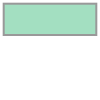

In [14]:
# -----------------------------
# Create bounding box from campus boundary
# -----------------------------

# Create a rectangular bounding box around the campus boundary
sgu_bbox = sgu_boundary.geometry.iloc[0].envelope

sgu_bbox

## Turn the bounding box into a GeoDataFrame

The bounding box we created is a single geometry object.

To use it with GeoPandas tools like `gpd.clip()`, we need to turn it into a GeoDataFrame.

In the code cell below, we place the bounding box inside the `geometry` argument and save the result as a new GeoDataFrame.

Fill in the blank for the bounding box variable name.

In [15]:
# -----------------------------
# Turn bounding box into a GeoDataFrame
# -----------------------------

sgu_bbox_gdf = gpd.GeoDataFrame(
    geometry=[sgu_bbox]
)

sgu_bbox_gdf

,geometry
0,"POLYGON ((-100.65351 43.2969, -100.61871 43.29..."


## Clip roads to the campus bounding box

Now we will clip the roads layer to the campus bounding box.

Clipping keeps only the parts of a spatial layer that fall inside another spatial shape. In this case, we want to keep only the road lines that fall inside the campus bounding box.

The function `gpd.clip()` takes two GeoDataFrames: the layer we want to clip, and the layer we want to use as the clipping boundary.

Fill in the blanks for the road lines GeoDataFrame and the bounding box GeoDataFrame.

In [16]:
# -----------------------------
# Clip roads to the campus bounding box
# -----------------------------

sgu_roads_clipped = gpd.clip(
    sgu_road_lines,
    sgu_bbox_gdf
)

sgu_roads_clipped

/tmp/ipykernel_7046/3842003595.py:5: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: EPSG:4326
Right CRS: None

  sgu_roads_clipped = gpd.clip(


geometry  \
element id                                                             
way     292806645  LINESTRING (-100.65273 43.2969, -100.65272 43....   
        897904680  LINESTRING (-100.62087 43.29911, -100.62107 43...   
        897904679  LINESTRING (-100.62292 43.30025, -100.62249 43...   
        897904681  LINESTRING (-100.62249 43.29991, -100.62293 43...   
        897904683  LINESTRING (-100.62305 43.29971, -100.62293 43...   
...                                                              ...   
        9924965    LINESTRING (-100.65197 43.30641, -100.65201 43...   
        9925053    LINESTRING (-100.64999 43.30726, -100.65075 43...   
        9924252    LINESTRING (-100.64738 43.30528, -100.64734 43...   
        9925050    LINESTRING (-100.65001 43.3075, -100.65009 43....   
        52697589   LINESTRING (-100.65267 43.30583, -100.65266 43...   

                       highway traffic_signals crossing  \
element id                                                
way     292806645        trunk             NaN      NaN   
        897904680      service             NaN      NaN   
        897904679      service             NaN      NaN   
        897904681      service             NaN      NaN   
        897904683      service             NaN      NaN   
...                        ...             ...      ...   
        9924965        service             NaN      NaN   
        9925053    residential             NaN      NaN   
        9924252    residential             NaN      NaN   
        9925050    residential             NaN      NaN   
        52697589   residential             NaN      NaN   

                                                                name  NHS  \
element id                                                                  
way     292806645  Blue Star Memorial Highway/Vietnam Veterans Me...  yes   
        897904680                                                NaN  NaN   
        897904679                                                NaN  NaN   
        897904681                                                NaN  NaN   
        897904683                                                NaN  NaN   
...                                                              ...  ...   
        9924965                                                  NaN  NaN   
        9925053                                           1st Street  NaN   
        9924252                                      Hillsider Drive  NaN   
        9925050                                  East Rosebud Street  NaN   
        52697589                                        Adams Street  NaN   

                          hgv hgv:national_network lanes    ref  ...  \
element id                                                       ...   
way     292806645  designated                  yes     2  US 83  ...   
        897904680         NaN                  NaN   NaN    NaN  ...   
        897904679         NaN                  NaN   NaN    NaN  ...   
        897904681         NaN                  NaN   NaN    NaN  ...   
        897904683         NaN                  NaN   NaN    NaN  ...   
...                       ...                  ...   ...    ...  ...   
        9924965           NaN                  NaN   NaN    NaN  ...   
        9925053           NaN                  NaN   NaN    NaN  ...   
        9924252           NaN                  NaN   NaN    NaN  ...   
        9925050           NaN                  NaN   NaN    NaN  ...   
        52697589          NaN                  NaN   NaN    NaN  ...   

                  tiger:source tiger:tlid tiger:upload_uuid service note  \
element id                                                                 
way     292806645          NaN        NaN               NaN     NaN  NaN   
        897904680          NaN        NaN               NaN     NaN  NaN   
        897904679          NaN        NaN               NaN     NaN  NaN   
        897904681          NaN      

## Plot the clipped roads

Now we will check the clipped roads layer by plotting it with the campus boundary and bounding box.

This map includes three layers:

- the bounding box
- the campus boundary
- the clipped roads

The bounding box helps us see the area used to clip the roads. The campus boundary shows the actual campus shape, and the clipped roads show only the road lines that fall inside the bounding box.

In the code cell below, fill in the blanks for the GeoDataFrame names, plotting parameters, and map title.

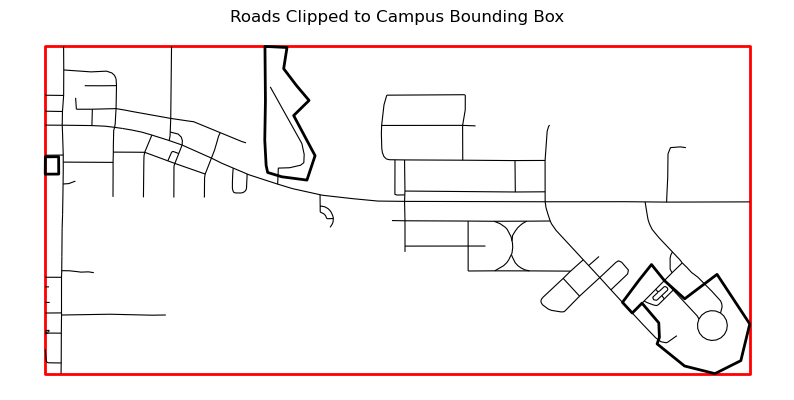

In [17]:
# -----------------------------
# Plot clipped roads with campus boundary and bounding box
# -----------------------------

fig, ax = plt.subplots(figsize=(10, 10))

sgu_bbox_gdf.plot(
    ax=ax,
    edgecolor="red",
    facecolor="none",
    linewidth=2
)

sgu_boundary.plot(
    ax=ax,
    edgecolor="black",
    facecolor="none",
    linewidth=2
)

sgu_roads_clipped.plot(
    ax=ax,
    color="black",
    linewidth=0.8
)

plt.title("Roads Clipped to Campus Bounding Box")
plt.axis("off")
plt.show()

## Find water features near campus

Next, we will search OpenStreetMap for water features near campus.

OpenStreetMap can store water in more than one way. In this example, we will use two tags: one for features labeled as natural water, and one for waterways such as streams, rivers, or drainage paths.

The function `ox.features_from_point()` searches for features within a set distance of the campus center point.

Fill in the blanks for the water tags.

In [18]:
# -----------------------------
# Find water features near campus
# -----------------------------

water_tags = {
    "natural": "water",
    "waterway": True
}

sgu_water = ox.features_from_point(
    center_lat_lon,
    tags=water_tags,
    dist=1000
)

sgu_water

geometry natural  \
element id                                                                      
way     263614031   POLYGON ((-100.61049 43.29444, -100.61113 43.2...   water   
        1523864871  POLYGON ((-100.63912 43.30577, -100.63907 43.3...   water   

                       source water  
element id                           
way     263614031   Bing 2012   NaN  
        1523864871        NaN  pond

## Plot water features

Now we will create a simple map of the water features near campus.

This layer may include features such as streams, ponds, rivers, drainage paths, or other water-related features, depending on what is available in OpenStreetMap.

The `.plot()` method lets us control how the water features appear on the map. The `color` parameter controls the color of the water features, and `linewidth` controls the thickness of any line features.

Fill in the blanks for the GeoDataFrame name, plotting parameters, and map title.

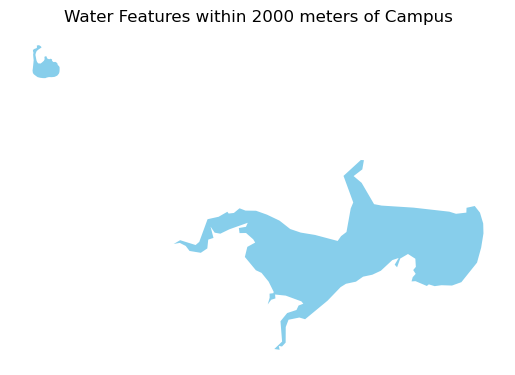

In [19]:
# -----------------------------
# Plot water features
# -----------------------------

sgu_water.plot(
    color="skyblue",
    linewidth=1
)

plt.title(f"Water Features within {search_distance} meters of Campus")
plt.axis("off")
plt.show()

## Create interactive map layers

Now we will create interactive versions of our map layers using `hvplot`.

Interactive maps let us zoom, pan, and explore the data more easily than a static map. We will create each layer separately first, and then combine them into one final map.

The `geo=True` argument tells `hvplot` that we are working with geographic data. The `tiles` argument adds a basemap underneath our data.

A few basemap options you can try are:

```python
tiles="CartoLight"
tiles="CartoDark"
tiles="OSM"
tiles="EsriImagery"
tiles="EsriStreet"
```

We'll start by creating an interactive layer of the campus boundary, then repeating that same workflow for the buildings, roads, and water layers.

In [20]:
# -----------------------------
# Create interactive boundary layer
# -----------------------------

boundary_layer = sgu_boundary.hvplot(
    geo=True,
    tiles=xyz.Esri.WorldStreetMap,
    line_color="black",
    fill_color="orange",
    fill_alpha=0.9,
    line_width=3,
    width=800,
    height=600,
    title="Sinte Gleska University Campus Boundary"
)

boundary_layer

:Overlay
   .WMTS.I     :WMTS   [Longitude,Latitude]
   .Polygons.I :Polygons   [Longitude,Latitude]

In [21]:
# -----------------------------
# Create interactive buildings layer
# -----------------------------

buildings_layer = sgu_buildings.hvplot(
    geo=True,
    tiles=xyz.Esri.WorldStreetMap,
    color="yellow",
    line_color="black",
    alpha=0.9,
    width=800,
    height=600,
    title="Buildings"
)

buildings_layer

:Overlay
   .WMTS.I     :WMTS   [Longitude,Latitude]
   .Polygons.I :Polygons   [Longitude,Latitude]

In [22]:
# -----------------------------
# Create interactive roads layer
# -----------------------------

roads_layer = sgu_roads_clipped.hvplot(
    geo=True,
    tiles="",
    color="grey",
    line_width=2,
    width=800,
    height=600,
    title="Roads"
)

roads_layer

:Path   [Longitude,Latitude]

In [23]:
# -----------------------------
# Create interactive water layer
# -----------------------------

water_layer = sgu_water.hvplot(
    geo=True,
    tiles="EsriImagery",
    color="blue",
    line_width=2,
    alpha=0.4,
    width=800,
    height=600,
    title="Water Features"
)

water_layer

:Overlay
   .WMTS.I     :WMTS   [Longitude,Latitude]
   .Polygons.I :Polygons   [Longitude,Latitude]

## Create the final interactive map

Finally, we will combine all of the interactive layers into one map.

In `hvplot`, the `*` symbol is used to overlay layers on top of each other. This lets us see the campus boundary, buildings, roads, water features, and basemap together in one interactive map.

The order of the layers matters. Layers listed later may appear on top of layers listed earlier.

Fill in the blanks below with the names of the four layers you just created and the run the cell.

In [24]:
# -----------------------------
# Create final interactive map
# -----------------------------

sgu_interactive_map = (
    boundary_layer
    * buildings_layer
    * roads_layer
    * water_layer
)

sgu_interactive_map

:Overlay
   .WMTS.I       :WMTS   [Longitude,Latitude]
   .Polygons.I   :Polygons   [Longitude,Latitude]
   .WMTS.II      :WMTS   [Longitude,Latitude]
   .Polygons.II  :Polygons   [Longitude,Latitude]
   .Path.I       :Path   [Longitude,Latitude]
   .WMTS.III     :WMTS   [Longitude,Latitude]
   .Polygons.III :Polygons   [Longitude,Latitude]

## Keep exploring

Now that you have built an interactive map of Sinte Gleska University, try using the same workflow for another campus or place.

You could try changing the `place_name` variable to another school, college, university, park, or neighborhood. Then rerun the notebook to see what OpenStreetMap data is available for that location.

Here are a few ideas to explore:

- Try mapping a different campus or community
- Change the `search_distance` value to include a larger or smaller area
- Try a different basemap, such as `"OSM"`, `"CartoDark"`, or `"EsriImagery"`
- Search for a different OpenStreetMap feature, such as parks, parking lots, sidewalks, or sports fields
- Compare how much building, road, or water data is available in different places
- Think about what data may be missing from OpenStreetMap and why that might matter

OpenStreetMap is created by people around the world, so some places may have more detailed data than others. As you explore, pay attention to what shows up, what does not show up, and what questions your map helps you ask.